# Dreamer checkpoint evaluation — IQM and 95% CI

Plots the saved checkpoints from ARC run `k0r409zk` (`arc-9199279-long`). Each checkpoint was evaluated on the same 64 track seeds, using the sampled policy. The saved 95% IQM intervals use 50,000 rliable percentile-bootstrap resamples over evaluation episodes.

Re-running this notebook only loads the saved benchmark results and redraws the figures. It does **not** rerun the environments. The interval describes evaluation-episode variability for a fixed checkpoint, rather than variation across independent training seeds.

A second plot shows the individual episode returns for the latest checkpoint in the report.

Styling follows the latest `env-difference.ipynb`: Routed Gothic, charcoal `#343633`, and off-white `#F7F4EB`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, MultipleLocator
import numpy as np

# Work from either the repository root or notebooks/plot_generation.
repo_root = next(
    parent
    for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "pyproject.toml").is_file()
    and (parent / "notebooks/plot_generation").is_dir()
)


## Settings

Change the input report, colours, figure size, axis limits, histogram bins, or export names here. The exported PNG and SVG go into `assets/`.

In [2]:
report_path = (
    repo_root
    / "experiments/dreamer/evaluations/arc-k0r409zk-all-checkpoints-64-20261028.json"
)
export_stem = repo_root / "assets/arc-checkpoint-iqm"
histogram_export_stem = repo_root / "assets/arc-latest-checkpoint-rewards"
histogram_bins = 12

blk = "#343633"
off_white = "#F7F4EB"
font_family = "Routed Gothic"
figure_size = (9, 3.8)
ci_alpha = 0.16
line_width = 1.5
marker_size = 4
x_tick_spacing = 10  # Thousands of training updates.
y_limits = (-100, 1000)
plot_title = "DREAMER - CHECKPOINT EVALUATION"

plt.rcParams.update({
    "font.family": font_family,
    "font.style": "normal",
    "font.size": 11,
    "figure.facecolor": off_white,
    "axes.facecolor": off_white,
    "figure.dpi": 120,
    "text.color": blk,
    "axes.labelcolor": blk,
    "axes.edgecolor": blk,
    "xtick.color": blk,
    "ytick.color": blk,
    "svg.fonttype": "none",  # Keep text editable in the SVG.
})


## Load the benchmark

The point estimates and confidence limits are read directly from the completed evaluation report. Step 0 is the untrained model. The x-axis uses gradient updates, not environment transitions.

In [3]:
report = json.loads(report_path.read_text())
assert np.isclose(report["confidence_level"], 0.95), "Expected a 95% CI report"
results = sorted(report["results"], key=lambda row: row["train_step"])

train_steps = np.array([row["train_step"] for row in results])
x = train_steps / 1000
# The evaluation script uses rliable.metrics.aggregate_iqm and its bootstrap API.
iqm = np.array([row["iqm"] for row in results])
ci = np.array([row["iqm_ci_95"] for row in results])
assert ci.shape == (len(results), 2)
assert np.isfinite(np.column_stack([iqm, ci])).all()

print(f"Run: {results[-1]['name']}")
print(f"Episodes per checkpoint: {report['num_episodes']}")
print(f"Bootstrap resamples: {report['bootstrap_reps']:,}")
print("\n  UPDATES       IQM             95% CI")
for step, value, (lower, upper) in zip(train_steps, iqm, ci):
    print(f"{step:9,}  {value:8.2f}    [{lower:7.2f}, {upper:7.2f}]")


Run: arc-9199279-long
Episodes per checkpoint: 64
Bootstrap resamples: 50,000

  UPDATES       IQM             95% CI
        0    -29.21    [ -30.86,  -27.49]
    1,600    -75.88    [ -76.45,  -75.28]
   17,600     12.23    [  -4.08,   29.28]
   33,600    475.81    [ 419.67,  531.24]
   49,600    658.15    [ 609.16,  707.91]
   65,600    654.27    [ 596.92,  710.82]
   81,600    859.56    [ 822.38,  877.43]


## Draw and export

Points mark the evaluated checkpoints; the connecting line is a visual guide. The band shows the saved 95% bootstrap interval. Edit this cell freely to adjust the presentation.

PNG: /Users/alexinch/noodling/a2i/world_models_paper/assets/arc-checkpoint-iqm.png
SVG: /Users/alexinch/noodling/a2i/world_models_paper/assets/arc-checkpoint-iqm.svg


<ipython-input-4-29e34bea77ef>:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f"{l.get_text()}k" for l in ax.get_xticklabels()])


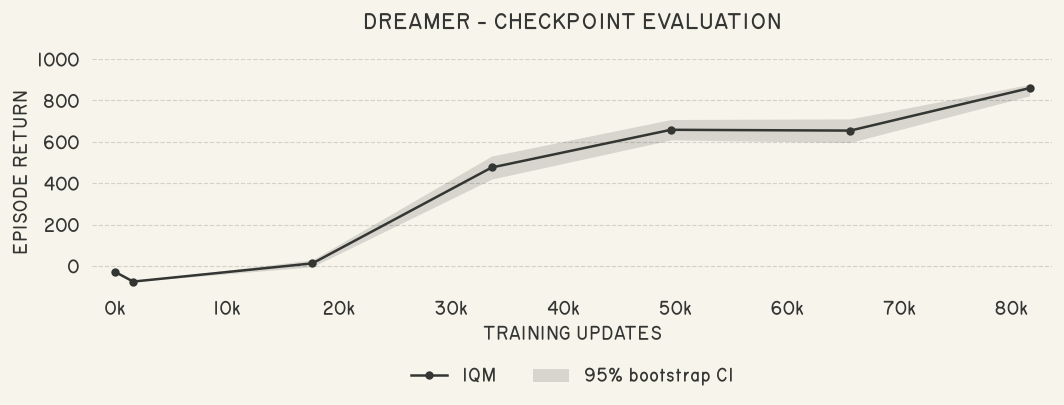

In [4]:
fig, ax = plt.subplots(figsize=figure_size)

ax.plot(
    x,
    iqm,
    color=blk,
    linewidth=line_width,
    marker="o",
    markersize=marker_size,
    label="IQM",
    zorder=3,
)
ax.fill_between(
    x,
    ci[:, 0],
    ci[:, 1],
    color=blk,
    alpha=ci_alpha,
    linewidth=0,
    label="95% bootstrap CI",
    zorder=1,
)

ax.set_xlabel("TRAINING UPDATES")
ax.set_ylabel("EPISODE RETURN")
ax.set_title(plot_title, pad=18)
ax.set_ylim(*y_limits)
ax.margins(x=0.025)
ax.xaxis.set_major_locator(MultipleLocator(x_tick_spacing))
ax.yaxis.set_major_locator(MultipleLocator(200))
ax.set_axisbelow(True)
ax.grid(axis="y", color=blk, alpha=0.18, linestyle="--", linewidth=0.7)
ax.spines[:].set_visible(False)
ax.tick_params(axis="both", length=0, pad=8)
ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.28),
    ncol=2,
)

# tick labels -> "10k"
ax.set_xticklabels([f"{l.get_text()}k" for l in ax.get_xticklabels()])

plt.tight_layout()
export_stem.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(export_stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(export_stem.with_suffix(".svg"), bbox_inches="tight")
plt.show()

print(f"PNG: {export_stem.with_suffix('.png')}")
print(f"SVG: {export_stem.with_suffix('.svg')}")


## Latest checkpoint: reward distribution

This histogram uses the saved, undiscounted episode returns from the latest checkpoint in the report. Bar heights count episodes; together they account for all 64 evaluations. Change `histogram_bins` in Settings to adjust the binning. Re-running this plot does not run any new evaluations.


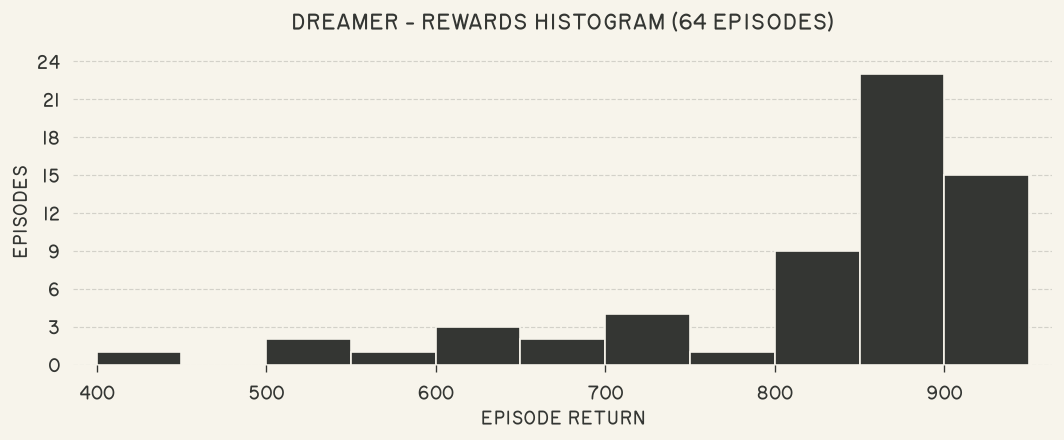

Checkpoint: arc-9199279-long / 81,600 updates
Episodes: 64
PNG: /Users/alexinch/noodling/a2i/world_models_paper/assets/arc-latest-checkpoint-rewards.png
SVG: /Users/alexinch/noodling/a2i/world_models_paper/assets/arc-latest-checkpoint-rewards.svg


In [33]:
latest = results[-1]  # Results are sorted by training updates above.
rewards = np.asarray(latest["returns"], dtype=float)
assert rewards.shape == (report["num_episodes"],)
assert np.isfinite(rewards).all()

hist_fig, hist_ax = plt.subplots(figsize=figure_size)
counts, bin_edges, _ = hist_ax.hist(
    rewards,
    bins=np.arange(400, 1000, 50),
    color=blk,
    edgecolor=off_white,
    linewidth=1,
    zorder=3,
)

hist_ax.set_xlabel("EPISODE RETURN")
hist_ax.set_ylabel("EPISODES")
hist_ax.set_title("DREAMER - REWARDS HISTOGRAM (64 EPISODES)", pad=18)
hist_ax.yaxis.set_major_locator(MaxNLocator(integer=True))
hist_ax.set_axisbelow(True)
hist_ax.grid(axis="y", color=blk, alpha=0.18, linestyle="--", linewidth=0.7)
hist_ax.spines[:].set_visible(False)
hist_ax.tick_params(axis="both", length=0, pad=8)
hist_ax.tick_params(axis="x", length=4, pad=8)
hist_ax.margins(x=0.025)

hist_fig.tight_layout()
histogram_export_stem.parent.mkdir(parents=True, exist_ok=True)
hist_fig.savefig(
    histogram_export_stem.with_suffix(".png"), dpi=300, bbox_inches="tight"
)
hist_fig.savefig(histogram_export_stem.with_suffix(".svg"), bbox_inches="tight")
plt.show()

print(f"Checkpoint: {latest['name']} / {latest['train_step']:,} updates")
print(f"Episodes: {len(rewards)}")
print(f"PNG: {histogram_export_stem.with_suffix('.png')}")
print(f"SVG: {histogram_export_stem.with_suffix('.svg')}")
